## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


> **Data note:** `GiveMeSomeCredit.csv` is the public Kaggle *Give Me Some Credit* training file (150,000 labelled customers, `cs-training`). It has no `SEX`, `EDUCATION` or `NumberOfDefault` columns, so the cells that use them are guarded with `if column in df.columns` and are skipped here; with the extended file they run unchanged.

## 2. Load the data

In [2]:
path_train ="GiveMeSomeCredit.csv"

data= pd.read_csv(path_train)

# The public Kaggle file has an unnamed index column and calls the target `SeriousDlqin2yrs`.
# Harmonise it with the names used in the rest of the notebook.
data = data.drop(columns=data.columns[data.columns.str.startswith("Unnamed")])
data = data.rename(columns={"SeriousDlqin2yrs": "SeriousDlqin"})

print("shape", data.shape)
data.head(10)

shape (150000, 11)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
5,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0
6,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0
7,0,0.754464,39,0,0.209940,3500.0,8,0,0,0,0.0
8,0,0.116951,27,0,46.000000,NaN,2,0,0,0,NaN
9,0,0.189169,57,0,0.606291,23684.0,9,0,4,0,2.0


In [3]:
df=data.copy()

## 3. Understand the structure


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [5]:
# SEX only exists in the extended version of the file; the public Kaggle file does not have it.
if "SEX" in df.columns:
    df["SEX"] = df["SEX"].map({"M": 0, "F": 1})

In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 150000
Number of columns: 11


## 4. Define the target


In [7]:
target = "SeriousDlqin"

print("Target:", target)
print("Unique values:")
print(df[target].unique())

Target: SeriousDlqin
Unique values:
[1 0]


In [8]:
target_summary = pd.DataFrame({
    "Count": df[target].value_counts(),
    "Percent": df[target].value_counts(normalize=True).mul(100).round(2)
})

target_summary

,Count,Percent
SeriousDlqin,,
0,139974,93.32
1,10026,6.68


## 5. Duplicate rows

In [9]:
duplicate_count = df.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)


Number of duplicated rows: 609


In [10]:
df[df.duplicated(keep=False)]


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
52,0,1.0,62,0,0.0,NaN,1,0,0,0,0.0
331,0,1.0,29,0,0.0,NaN,0,0,0,0,0.0
530,0,0.0,82,0,0.0,NaN,3,0,0,0,0.0
1250,0,0.0,84,0,0.0,NaN,1,0,0,0,0.0
1669,0,1.0,29,0,0.0,NaN,0,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
149139,0,0.0,77,0,0.0,NaN,2,0,0,0,0.0
149431,0,1.0,25,0,0.0,NaN,1,0,0,0,NaN
149472,0,1.0,84,0,0.0,NaN,1,0,0,0,0.0
149769,0,1.0,23,98,0.0,NaN,0,98,0,98,NaN


## 6. Linear Correlation

In [11]:
corr = df.corr()

corr[target].sort_values(ascending=False)

SeriousDlqin                            1.000000
NumberOfTime30-59DaysPastDueNotWorse    0.125587
NumberOfTimes90DaysLate                 0.117175
NumberOfTime60-89DaysPastDueNotWorse    0.102261
NumberOfDependents                      0.046048
RevolvingUtilizationOfUnsecuredLines   -0.001802
NumberRealEstateLoansOrLines           -0.007038
DebtRatio                              -0.007602
MonthlyIncome                          -0.019746
NumberOfOpenCreditLinesAndLoans        -0.029669
age                                    -0.115386
Name: SeriousDlqin, dtype: float64

## 7. Target Leakage

In [12]:
if "NumberOfDefault" in df.columns:
    print(df[["NumberOfDefault", target]].head(20))
else:
    print("No NumberOfDefault column in this file: nothing to check for leakage.")


No NumberOfDefault column in this file: nothing to check for leakage.


In [13]:
df = df.drop(columns=["NumberOfDefault"], errors="ignore")

print("Leaked feature removed (if present).")

Leaked feature removed (if present).


## 8. Data validation: impossible value


In [14]:
print("Age < 18:", (df["age"] < 18).sum())
print("Age > 100:", (df["age"] > 100).sum())
print("MonthlyIncome < 0:", (df["MonthlyIncome"] < 0).sum())
print("NumberOfTimes90DaysLate < 0:", (df["NumberOfTimes90DaysLate"] < 0).sum())
print("NumberRealEstateLoansOrLines < 0:", (df["NumberRealEstateLoansOrLines"] < 0).sum())

Age < 18: 1
Age > 100: 13
MonthlyIncome < 0: 0
NumberOfTimes90DaysLate < 0: 0
NumberRealEstateLoansOrLines < 0: 0


In [15]:
df = df[(df["age"] >= 18) & (df["age"] <= 100)]

## 9. Train-Test Split

In [16]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (104990, 10)
X_test : (44996, 10)
y_train: (104990,)
y_test : (44996,)


In [17]:
print("Overall:")
print(y.value_counts(normalize=True).mul(100).round(2))

print("\nTrain:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Overall:
SeriousDlqin
0    93.32
1     6.68
Name: proportion, dtype: float64

Train:
SeriousDlqin
0    93.32
1     6.68
Name: proportion, dtype: float64

Test:
SeriousDlqin
0    93.31
1     6.69
Name: proportion, dtype: float64


In [18]:
train_df = X_train.copy()
train_df[target] = y_train

print("Train dataframe shape:", train_df.shape)
train_df.head()

Train dataframe shape: (104990, 11)


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin
38102,0.000000,45,0,0.460931,3416.0,5,0,2,0,2.0,0
111974,0.639249,42,1,0.259114,19666.0,10,0,1,0,3.0,0
115712,0.058665,44,0,0.295182,4254.0,12,0,2,0,1.0,0
119235,0.016730,49,0,9.000000,NaN,1,0,0,0,0.0,0
88057,0.380152,61,0,8268.000000,NaN,25,0,7,0,0.0,0


In [19]:
test_df = X_test.copy()
test_df[target] = y_test

print("Train dataframe shape:", test_df.shape)
test_df.head()

Train dataframe shape: (44996, 11)


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin
140392,0.727458,44,3,0.778059,7100.0,8,0,1,1,3.0,1
94065,0.002731,74,0,0.000000,NaN,4,0,0,0,NaN,0
103070,0.080355,50,0,135.000000,NaN,5,0,0,0,2.0,0
141290,0.489061,42,0,1603.000000,NaN,11,0,0,0,3.0,0
36347,0.042558,86,0,0.004428,7000.0,7,0,0,0,0.0,0


## 10. Missing value

In [20]:
missing_train = pd.DataFrame({
    "Missing_Count": train_df.isnull().sum(),
    "Missing_Percent": (
        train_df.isnull().mean().mul(100).round(2)
    )
})

missing_train = missing_train.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_train

,Missing_Count,Missing_Percent
MonthlyIncome,20702,19.72
NumberOfDependents,2711,2.58
RevolvingUtilizationOfUnsecuredLines,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
age,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
DebtRatio,0,0.00
NumberOfTimes90DaysLate,0,0.00
NumberRealEstateLoansOrLines,0,0.00
NumberOfTime60-89DaysPastDueNotWorse,0,0.00


In [21]:
train_df.groupby(
    train_df["MonthlyIncome"].isna()
)["SeriousDlqin"].mean()

MonthlyIncome
False    0.069796
True     0.054777
Name: SeriousDlqin, dtype: float64

In [22]:
train_df.groupby(
    train_df["NumberOfDependents"].isna()
)["SeriousDlqin"].mean()

NumberOfDependents
False    0.067443
True     0.043895
Name: SeriousDlqin, dtype: float64

In [23]:
# Missing values in Test
missing_test = pd.DataFrame({
    "Missing_Count": test_df.isnull().sum(),
    "Missing_Percent": test_df.isnull().mean().mul(100).round(2)
})

missing_test = missing_test.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_test

,Missing_Count,Missing_Percent
MonthlyIncome,9022,20.05
NumberOfDependents,1210,2.69
RevolvingUtilizationOfUnsecuredLines,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
age,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
DebtRatio,0,0.00
NumberOfTimes90DaysLate,0,0.00
NumberRealEstateLoansOrLines,0,0.00
NumberOfTime60-89DaysPastDueNotWorse,0,0.00


In [24]:
# Train
train_df["MonthlyIncome_missing"] = (
    train_df["MonthlyIncome"].isna().astype(int)
)

# Test
test_df["MonthlyIncome_missing"] = (
    test_df["MonthlyIncome"].isna().astype(int)
)

In [25]:
income_median = train_df["MonthlyIncome"].median()

train_df["MonthlyIncome"] = train_df["MonthlyIncome"].fillna(
    income_median
)

test_df["MonthlyIncome"] = test_df["MonthlyIncome"].fillna(
    income_median
)

In [26]:
dependents_median = train_df["NumberOfDependents"].median()

train_df["NumberOfDependents"] = train_df[
    "NumberOfDependents"
].fillna(dependents_median)

test_df["NumberOfDependents"] = test_df[
    "NumberOfDependents"
].fillna(dependents_median)

 ## 11. Outlier analysis

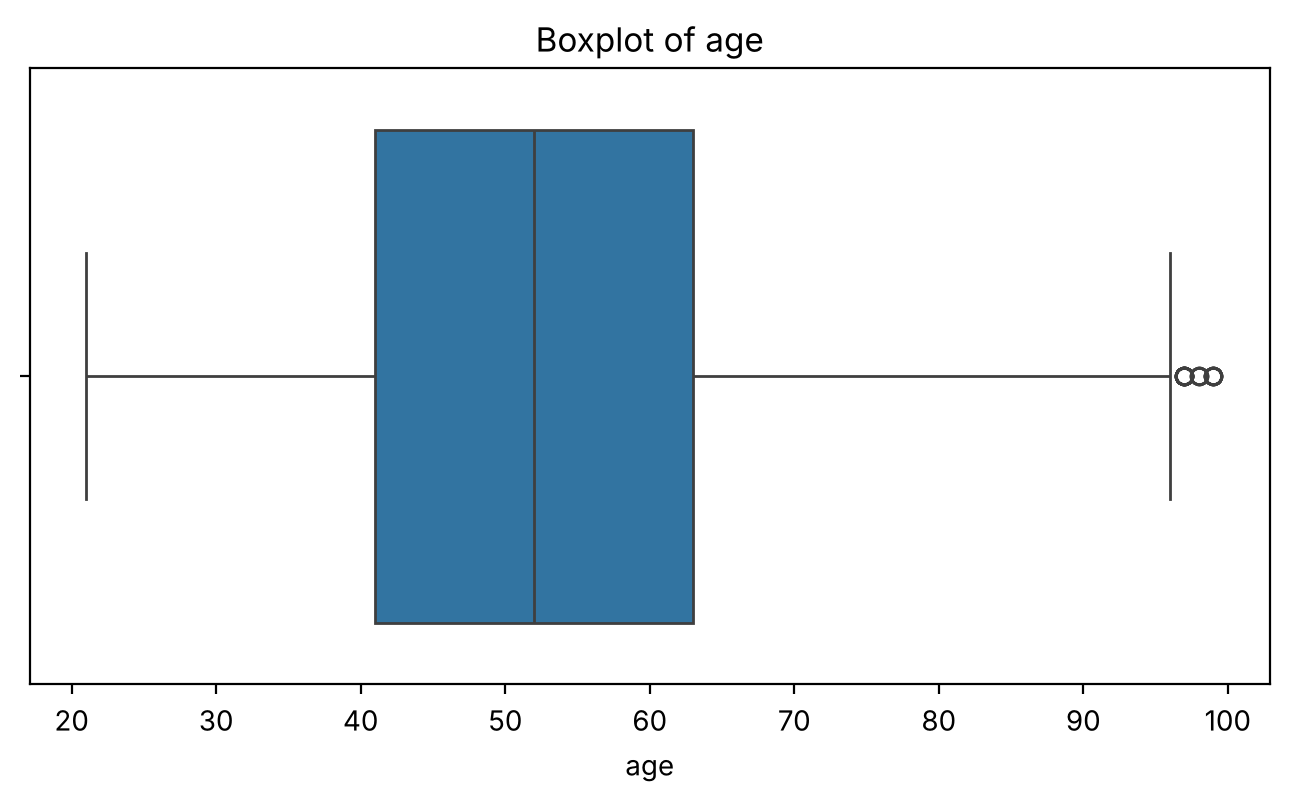

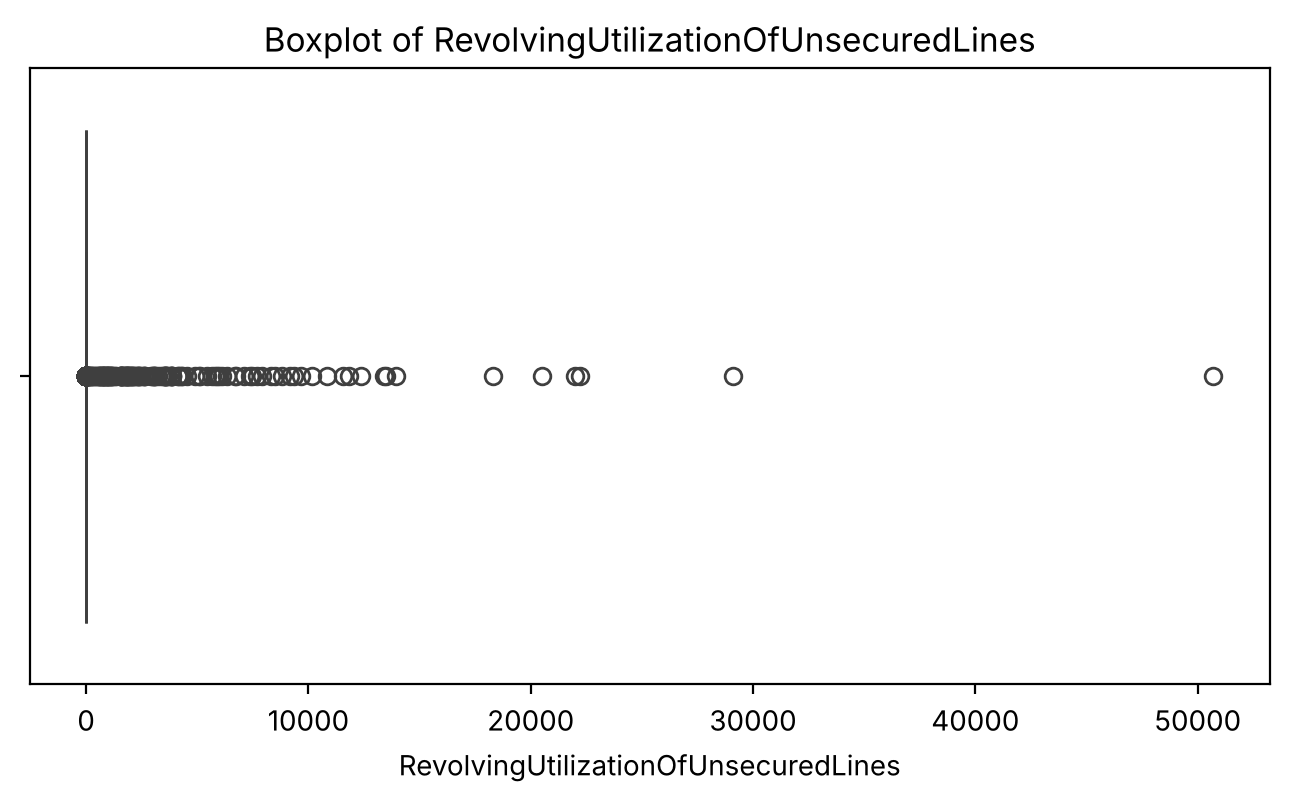

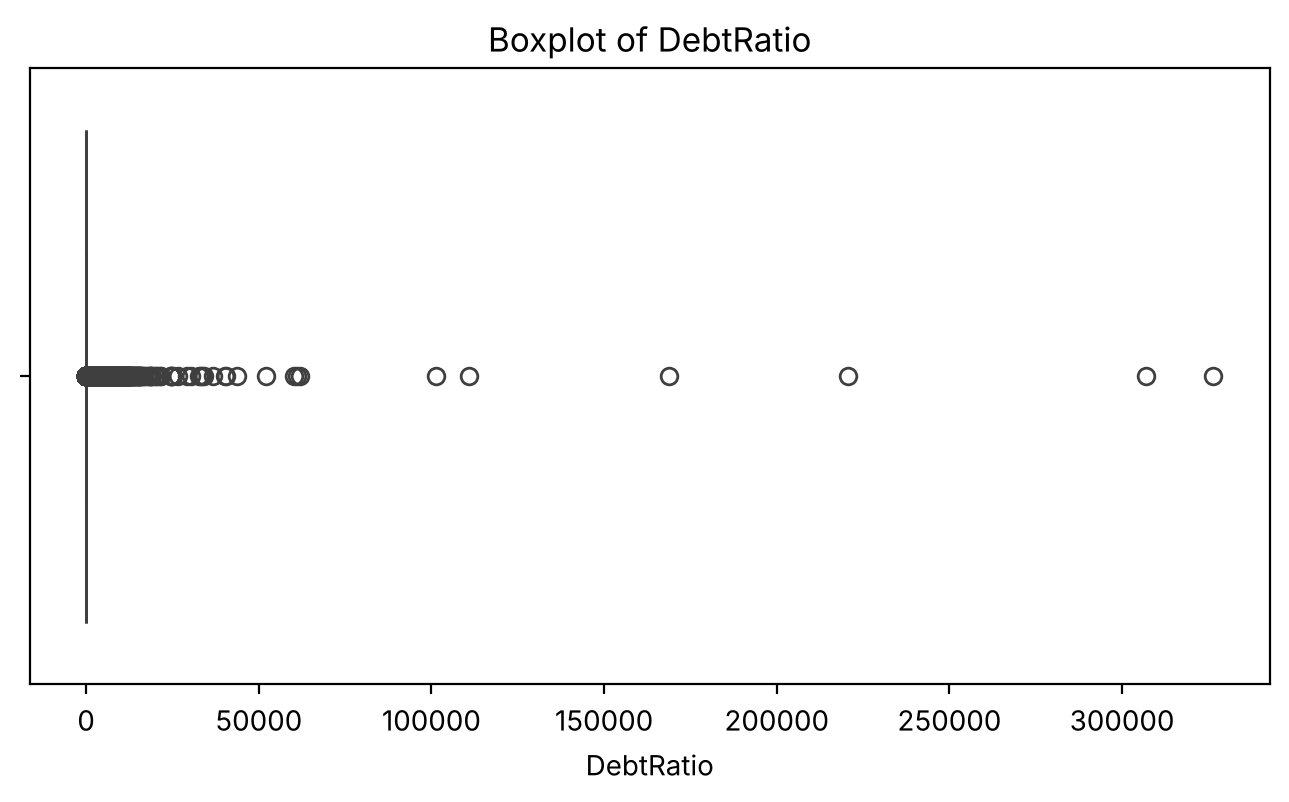

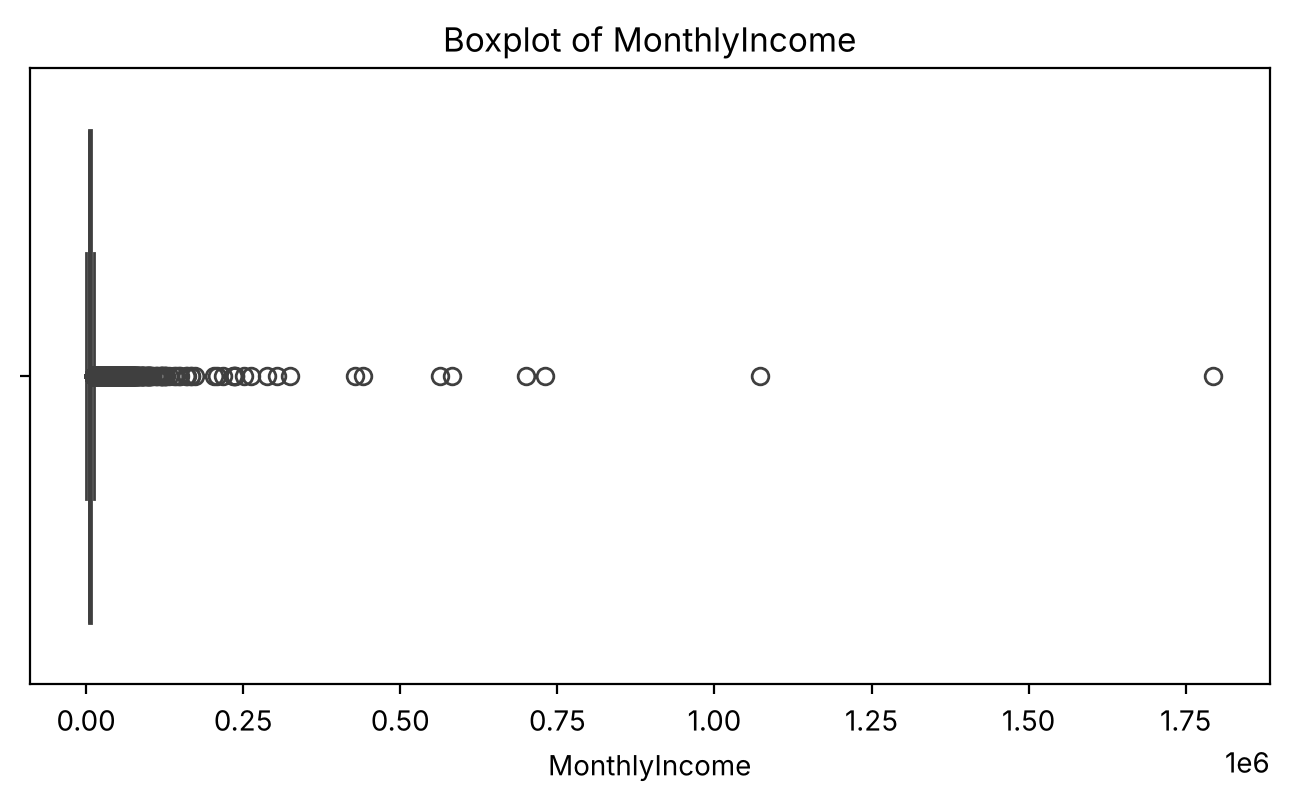

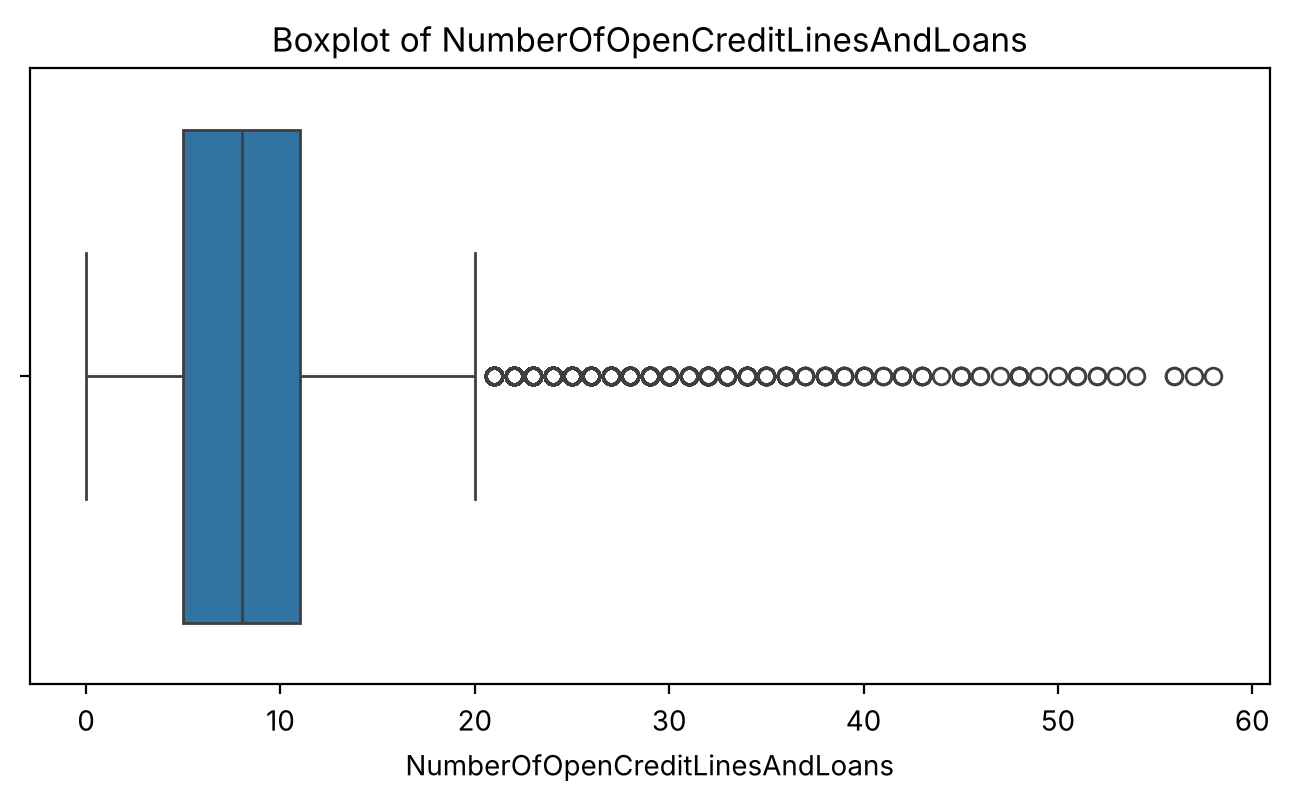

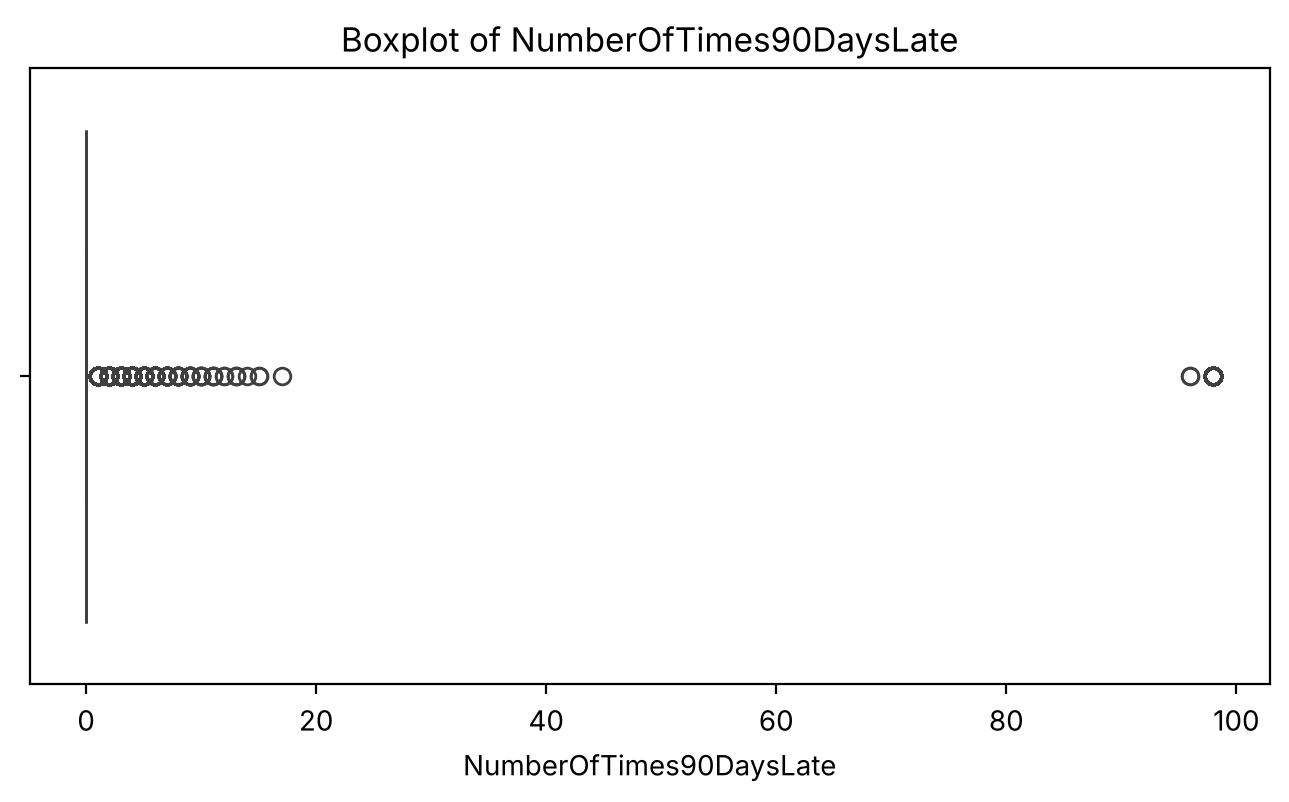

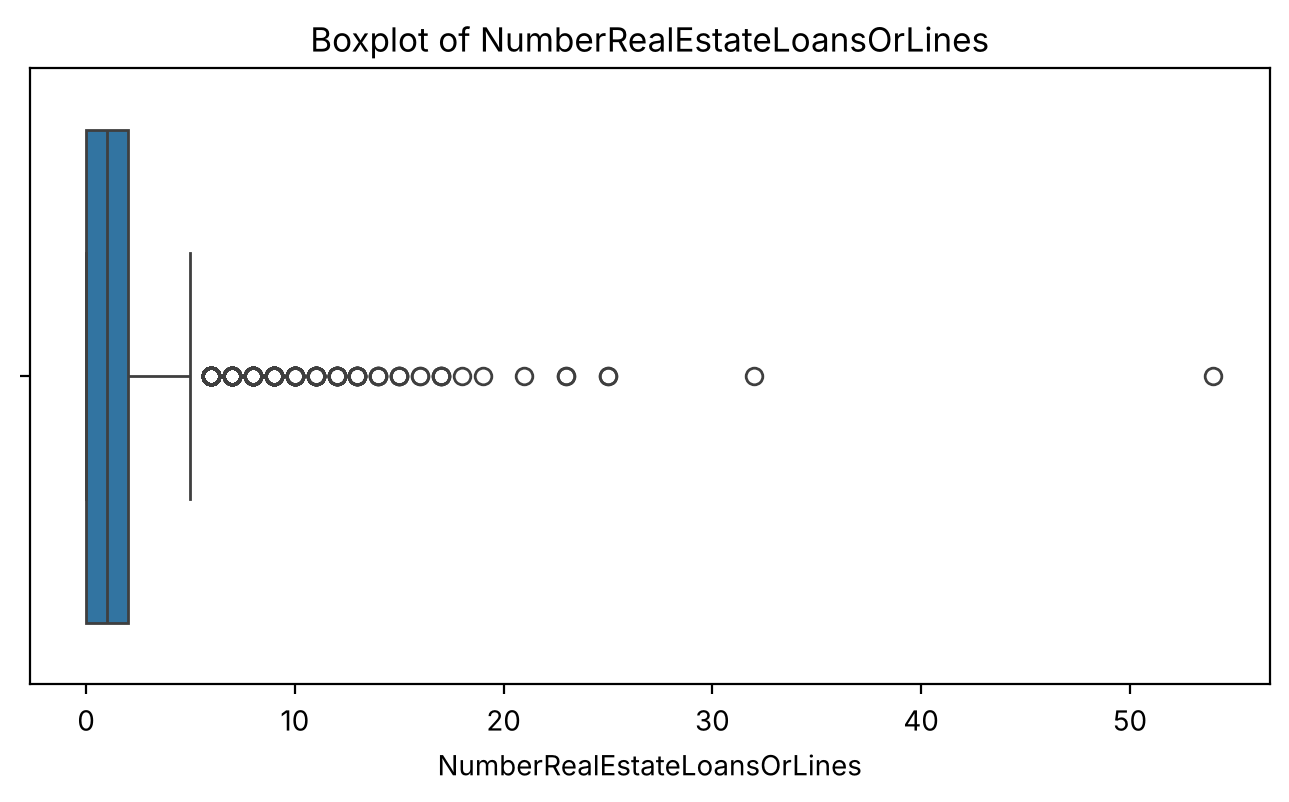

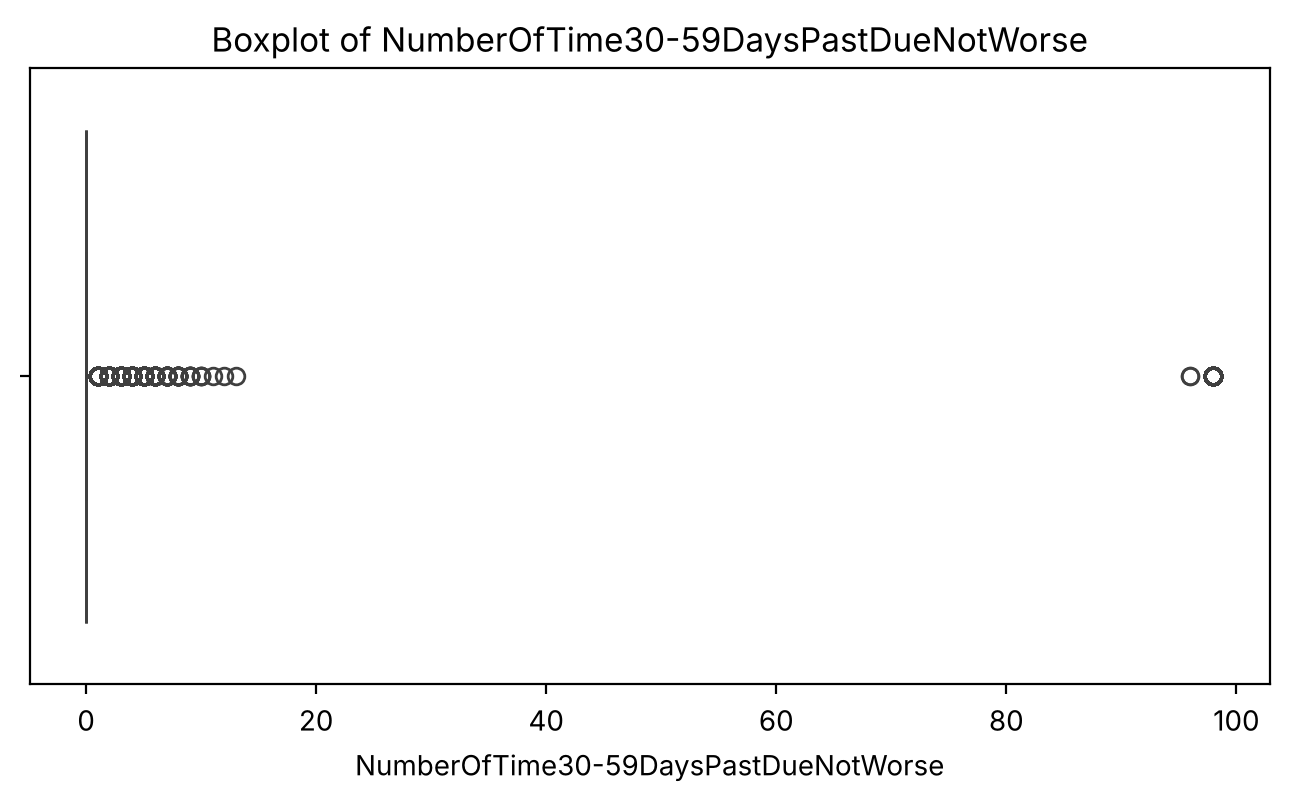

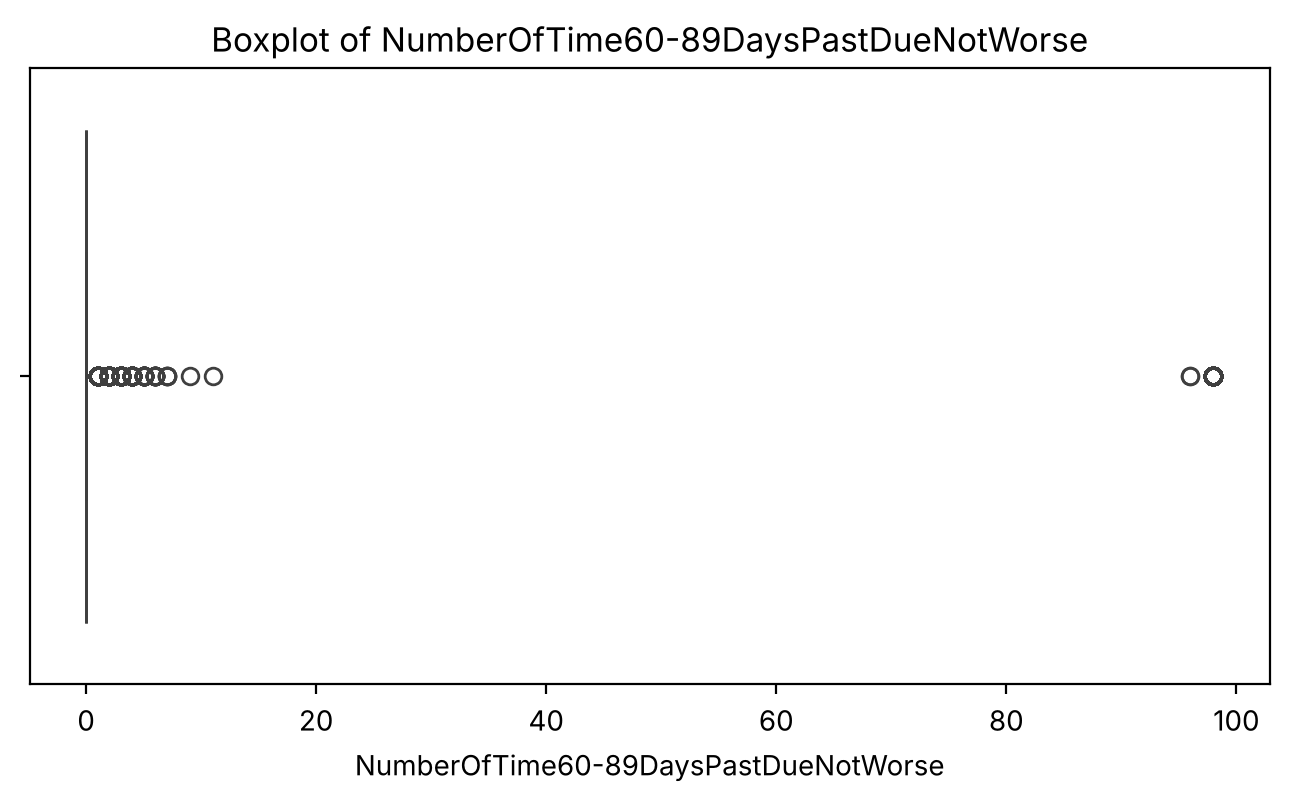

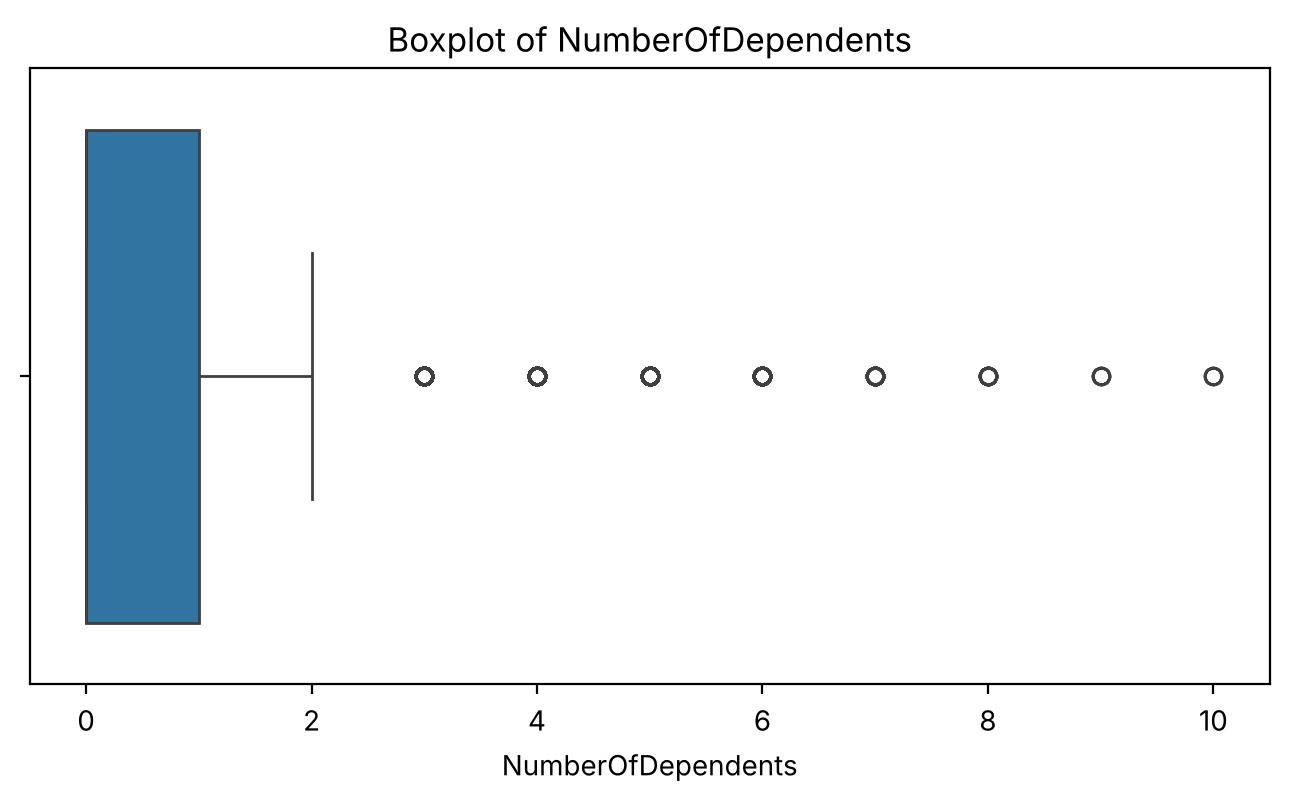

In [27]:
numeric_columns = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

for col in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train_df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [28]:
numeric_cols = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

train_df["Is_Outlier"] = False

outlier_report = []

for col in numeric_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    col_outlier = (
        (train_df[col] < lower) |
        (train_df[col] > upper)
    )

    train_df["Is_Outlier"] = (
        train_df["Is_Outlier"] |
        col_outlier
    )

    count = ((train_df[col] < lower) | (train_df[col] > upper)).sum()

    outlier_report.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Candidate_Outliers": count,
        "Outlier_Percent": round(count / len(train_df) * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_report)
outlier_report.sort_values("Outlier_Percent", ascending=False)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Candidate_Outliers,Outlier_Percent
2,DebtRatio,0.175375,0.864137,0.688762,-0.857768,1.897280,21840,20.80
7,NumberOfTime30-59DaysPastDueNotWorse,0.000000,0.000000,0.000000,0.000000,0.000000,16850,16.05
9,NumberOfDependents,0.000000,1.000000,1.000000,-1.500000,2.500000,9378,8.93
3,MonthlyIncome,3900.000000,7396.000000,3496.000000,-1344.000000,12640.000000,6442,6.14
5,NumberOfTimes90DaysLate,0.000000,0.000000,0.000000,0.000000,0.000000,5872,5.59
8,NumberOfTime60-89DaysPastDueNotWorse,0.000000,0.000000,0.000000,0.000000,0.000000,5344,5.09
4,NumberOfOpenCreditLinesAndLoans,5.000000,11.000000,6.000000,-4.000000,20.000000,2831,2.70
1,RevolvingUtilizationOfUnsecuredLines,0.029839,0.562561,0.532721,-0.769243,1.361643,542,0.52
6,NumberRealEstateLoansOrLines,0.000000,2.000000,2.000000,-3.000000,5.000000,546,0.52
0,age,41.000000,63.000000,22.000000,8.000000,96.000000,23,0.02


In [29]:
outlier_distribution = (
    train_df[train_df["Is_Outlier"]]["SeriousDlqin"]
    .value_counts()
    .sort_index()
)

print(outlier_distribution)

SeriousDlqin
0    46127
1     5470
Name: count, dtype: int64


## 12. Univariate relationship with target


In [30]:
features_to_compare = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

train_df.groupby(target)[features_to_compare].mean().T

SeriousDlqin,0,1
age,52.772090,46.020379
RevolvingUtilizationOfUnsecuredLines,6.715405,5.053453
DebtRatio,357.888747,277.586734
MonthlyIncome,6447.621334,5584.101895
NumberOfOpenCreditLinesAndLoans,8.498668,7.871455
NumberOfTimes90DaysLate,0.144958,2.082799
NumberRealEstateLoansOrLines,1.021118,0.980761
NumberOfTime30-59DaysPastDueNotWorse,0.290131,2.362548
NumberOfTime60-89DaysPastDueNotWorse,0.135905,1.817301
NumberOfDependents,0.725965,0.927604


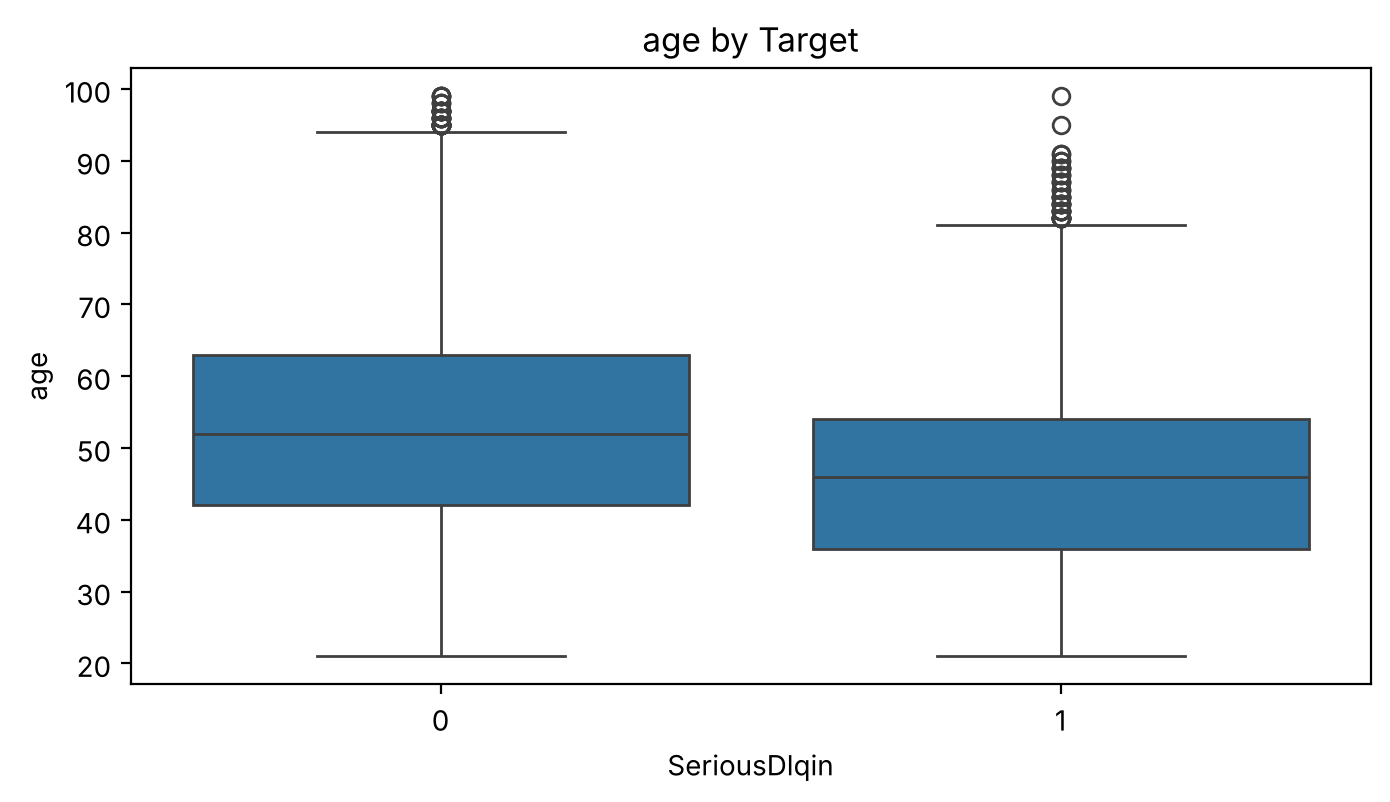

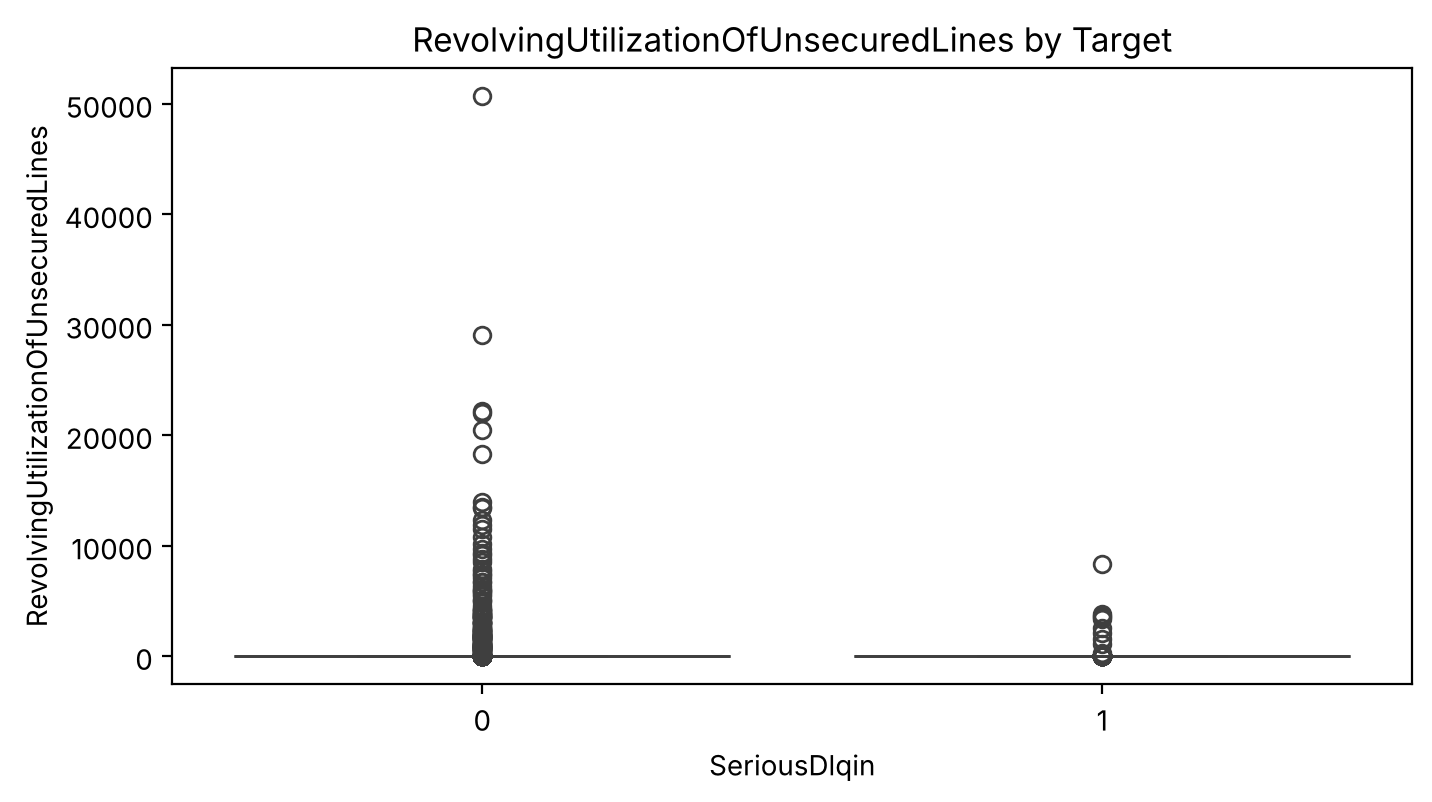

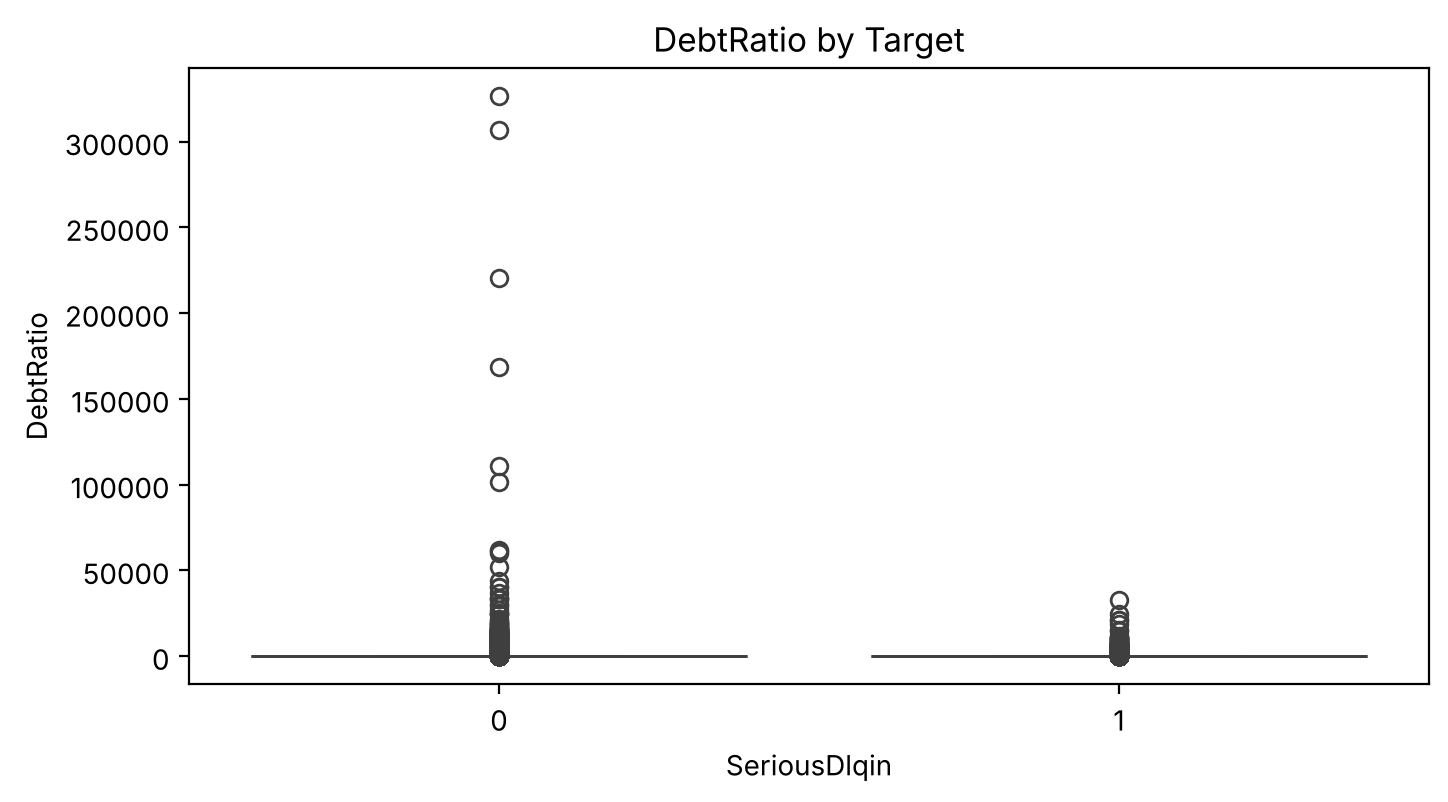

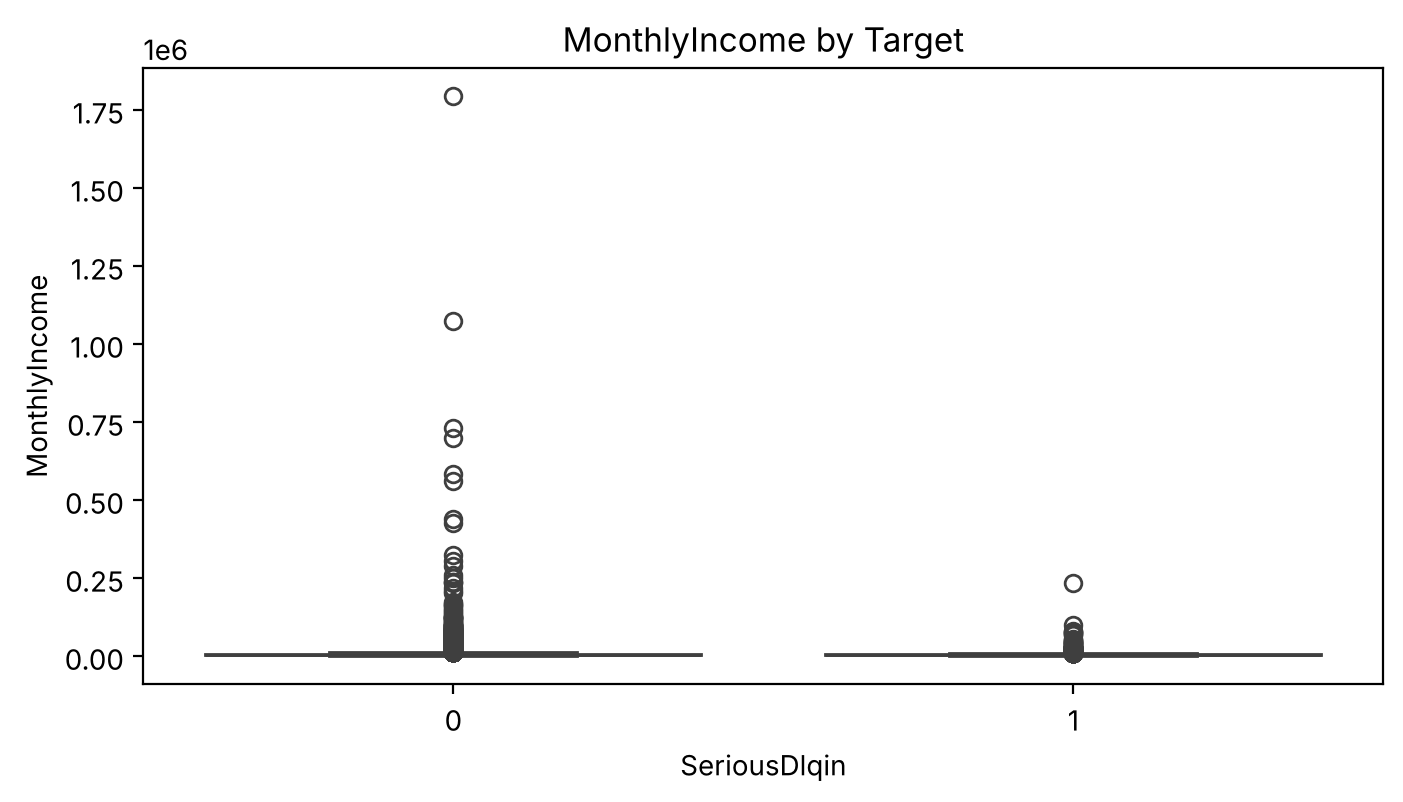

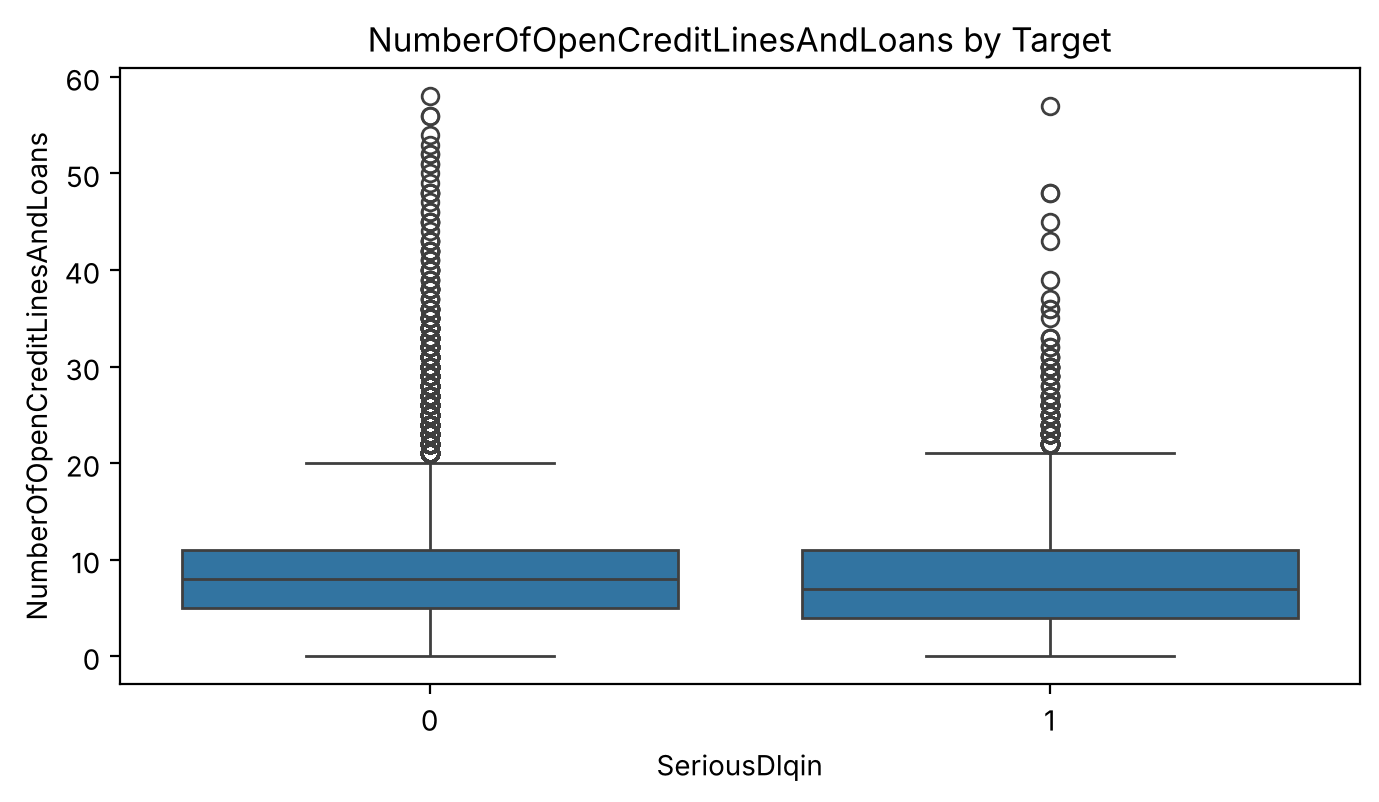

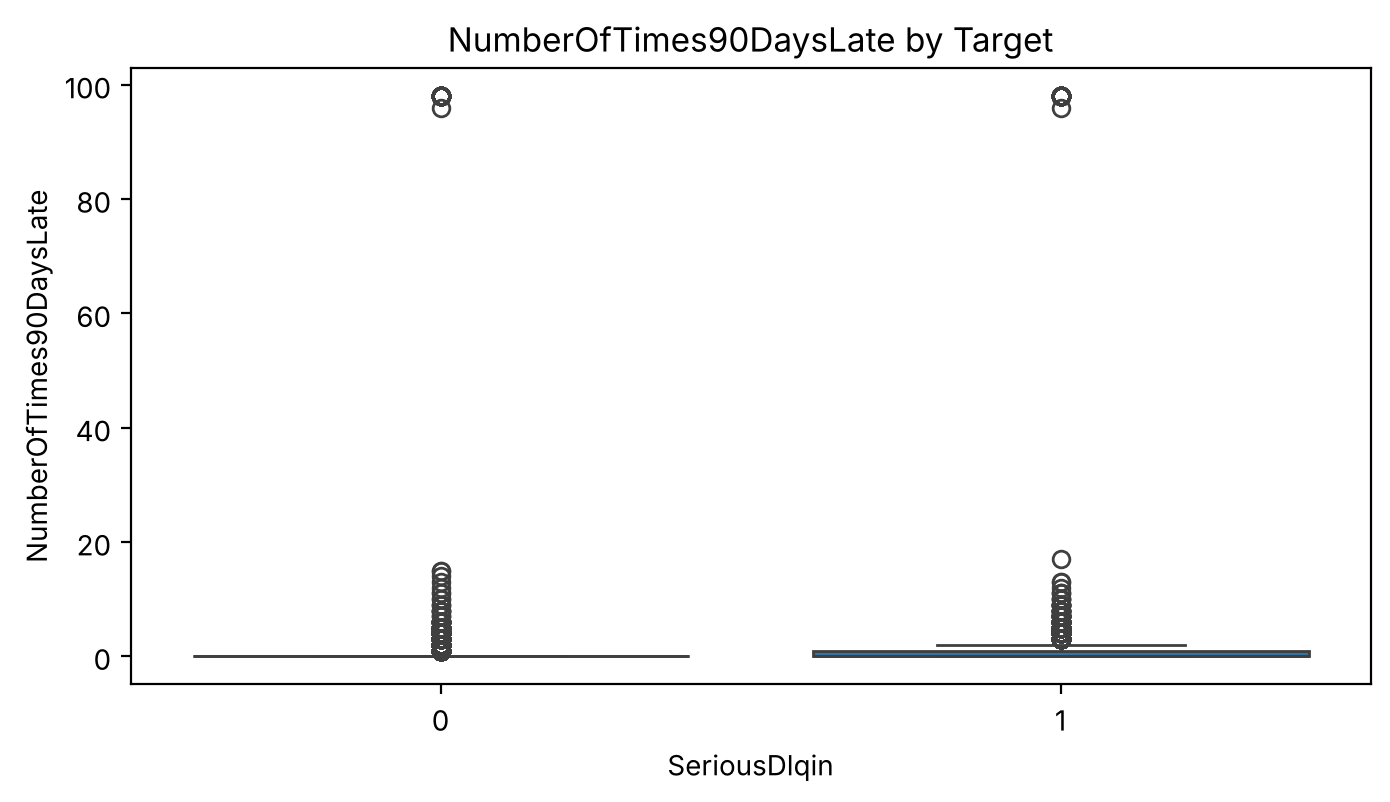

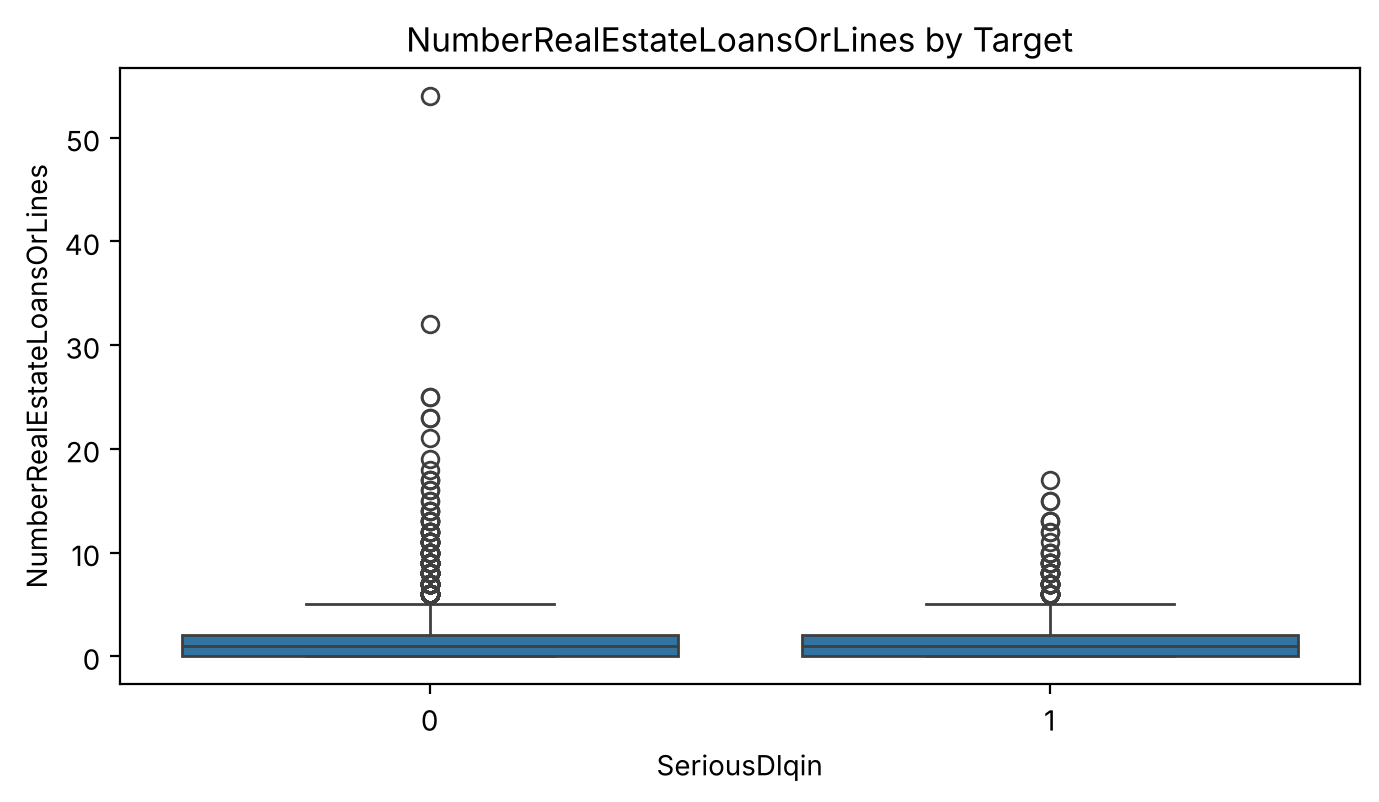

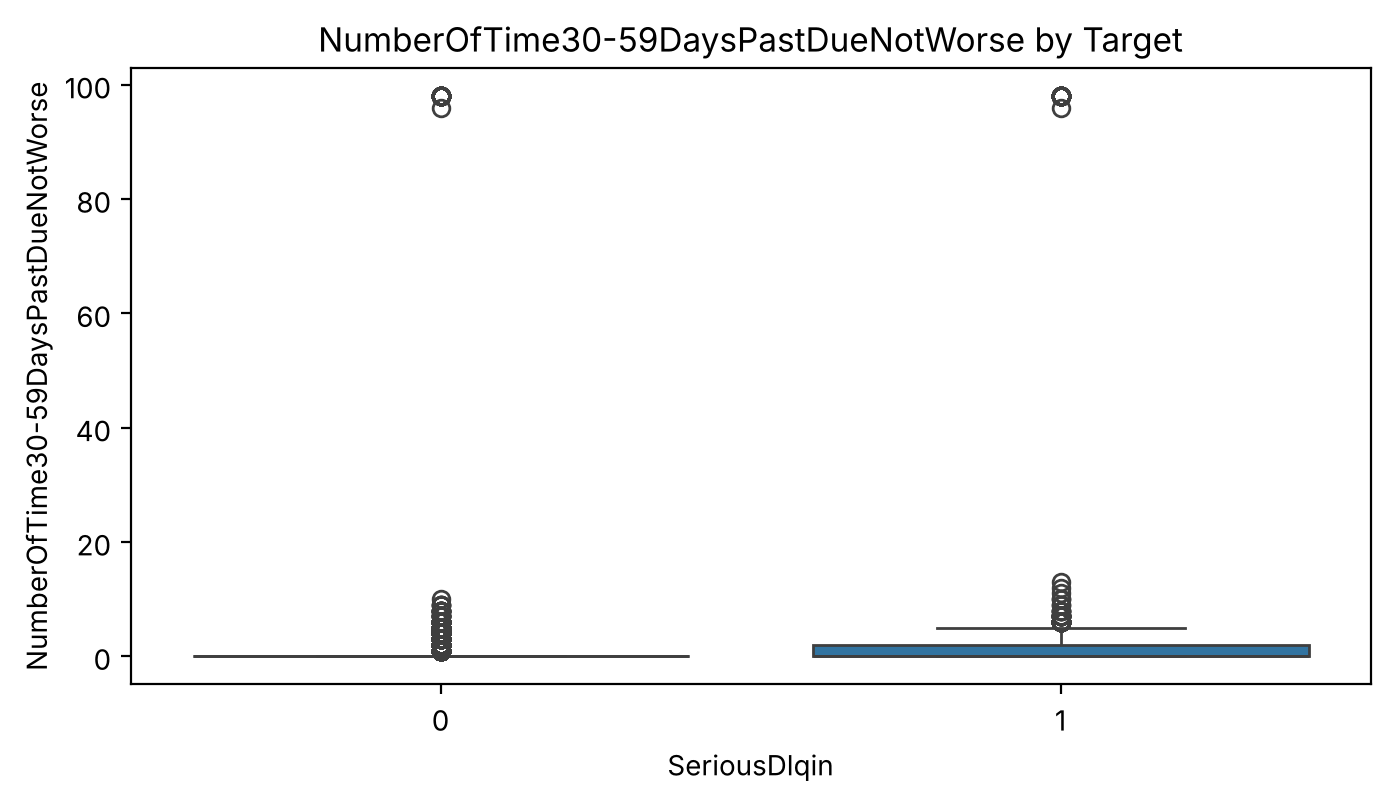

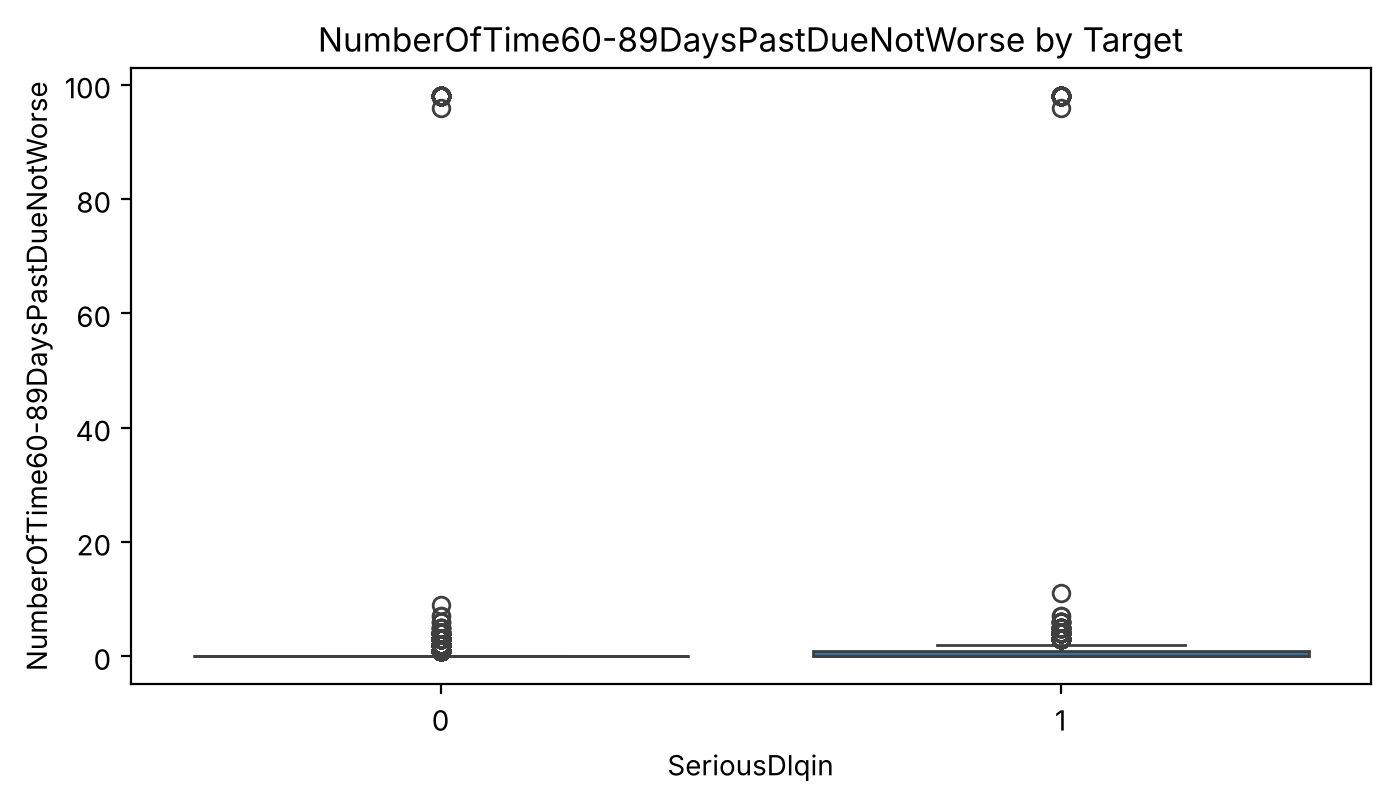

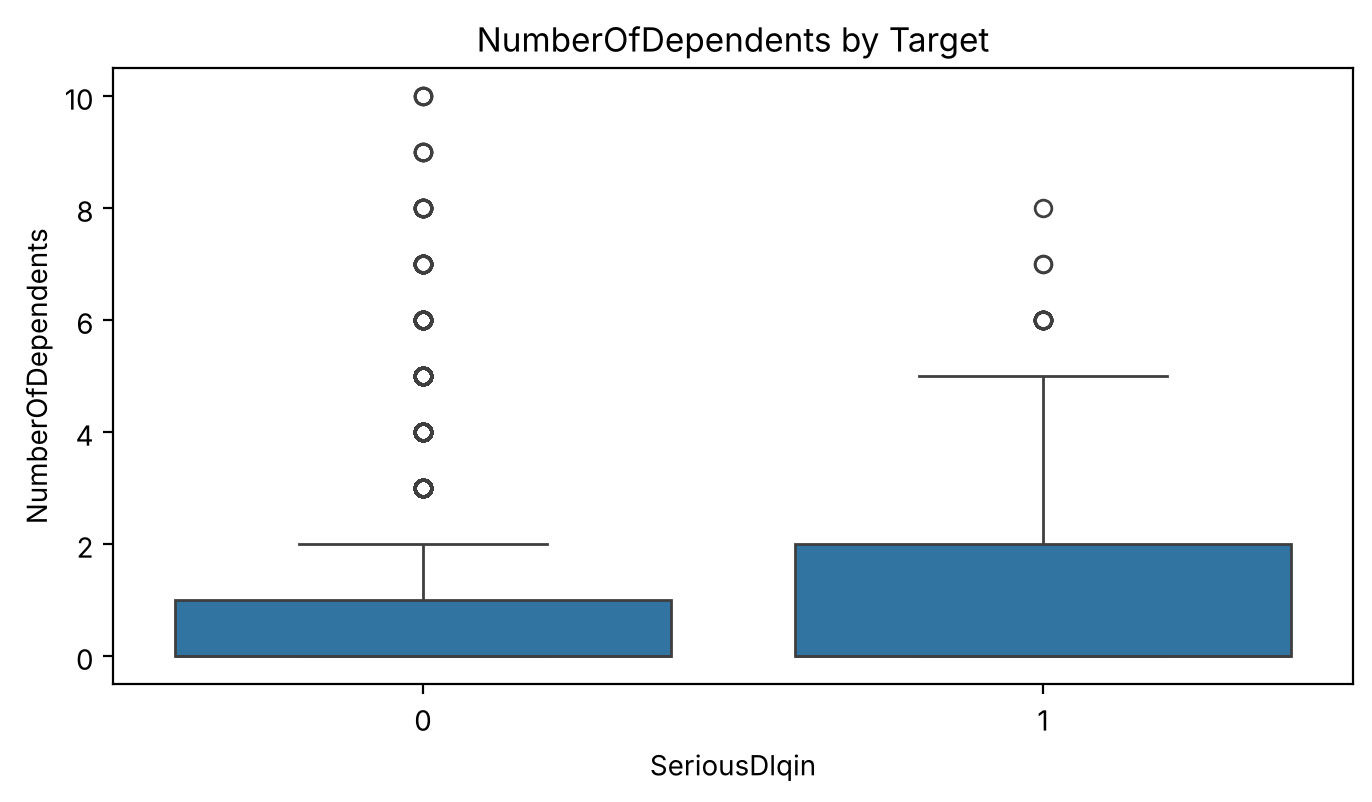

In [31]:
numeric_cols = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=train_df, x=target, y=col)
    plt.title(f"{col} by Target")
    plt.show()

## 13. Categorical analysis

In [32]:
# Check the new categorical features
for cat in ["SEX", "EDUCATION"]:
    if cat in train_df.columns:
        print(train_df[cat].value_counts().sort_index())
        print()
    else:
        print(f"{cat}: not available in this file")

SEX: not available in this file
EDUCATION: not available in this file


In [33]:
if "SEX" in train_df.columns:
    sex_risk = train_df.groupby("SEX")[target].agg(Customers="size", Bad_Rate="mean")
    sex_risk["Bad_Rate"] *= 100
    display(sex_risk)

In [34]:
if "EDUCATION" in train_df.columns:
    education_risk = train_df.groupby("EDUCATION")[target].agg(Customers="size", Bad_Rate="mean")
    education_risk["Bad_Rate"] *= 100
    display(education_risk)

## 14. Feature Engineering

In [35]:
train_df["TotalPastDue"] = (
    train_df["NumberOfTime30-59DaysPastDueNotWorse"]
    + train_df["NumberOfTime60-89DaysPastDueNotWorse"]
    + train_df["NumberOfTimes90DaysLate"]
)

train_df[[
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalPastDue"
]].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue
38102,0,0,0,0
111974,1,0,0,1
115712,0,0,0,0
119235,0,0,0,0
88057,0,0,0,0


In [36]:
test_df["TotalPastDue"] = (
    test_df["NumberOfTime30-59DaysPastDueNotWorse"]
    + test_df["NumberOfTime60-89DaysPastDueNotWorse"]
    + test_df["NumberOfTimes90DaysLate"]
)

test_df[[
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalPastDue"
]].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue
140392,3,1,0,4
94065,0,0,0,0
103070,0,0,0,0
141290,0,0,0,0
36347,0,0,0,0


In [37]:
train_df["Has90DaysLate"] = (train_df["NumberOfTimes90DaysLate"] > 0).astype(int)

train_df["Has90DaysLate"].value_counts()

Has90DaysLate
0    99118
1     5872
Name: count, dtype: int64

In [38]:
test_df["Has90DaysLate"] = (test_df["NumberOfTimes90DaysLate"] > 0).astype(int)

test_df["Has90DaysLate"].value_counts()

Has90DaysLate
0    42530
1     2466
Name: count, dtype: int64

In [39]:
pd.crosstab(
    train_df["Has90DaysLate"],
    train_df[target],
    normalize="index"
).round(3)

SeriousDlqin,0,1
Has90DaysLate,,
0,0.954,0.046
1,0.584,0.416


In [40]:
def get_worst_delay_status(row):
    if row["NumberOfTimes90DaysLate"] > 0:
        return 3
    elif row["NumberOfTime60-89DaysPastDueNotWorse"] > 0:
        return 2
    elif row["NumberOfTime30-59DaysPastDueNotWorse"] > 0:
        return 1
    else:
        return 0


train_df["WorstDelayStatus"] = train_df.apply(get_worst_delay_status, axis=1)
test_df["WorstDelayStatus"] = test_df.apply(get_worst_delay_status, axis=1)

## 15. Binning

In [41]:
bins = [0, 29, 39, 49, 59, 69, np.inf]
labels = ["<30", "30-39", "40-49", "50-59", "60-69", "70+"]

train_df["AgeGroup"] = pd.cut(
    train_df["age"],
    bins=bins,
    labels=labels
)

train_df["AgeGroup"].value_counts().sort_index()

AgeGroup
<30       6110
30-39    16267
40-49    23926
50-59    24776
60-69    20320
70+      13591
Name: count, dtype: int64

In [42]:
_, bins = pd.qcut(
    train_df["DebtRatio"],
    q=5,
    retbins=True,
    duplicates="drop"
)

train_df["DebtRatioGroup"] = pd.cut(
    train_df["DebtRatio"],
    bins=bins
)

## 16. WOE and Information Value


In [43]:
woe_table = train_df.groupby(
    "AgeGroup",
    observed=False
)[target].agg(
    Total="size",
    Bad="sum"
)

woe_table["Good"] = woe_table["Total"] - woe_table["Bad"]

woe_table

,Total,Bad,Good
AgeGroup,,,
<30,6110,707,5403
30-39,16267,1647,14620
40-49,23926,1987,21939
50-59,24776,1612,23164
60-69,20320,741,19579
70+,13591,323,13268


In [44]:
woe_table["Bad_Dist"] = (
    woe_table["Bad"] / woe_table["Bad"].sum()
)

woe_table["Good_Dist"] = (
    woe_table["Good"] / woe_table["Good"].sum()
)

In [45]:
woe_table["WOE"] = np.log(
    woe_table["Good_Dist"] /
    woe_table["Bad_Dist"]
)

woe_table["IV"] = (
    woe_table["Good_Dist"] -
    woe_table["Bad_Dist"]
) * woe_table["WOE"]

In [46]:
IV = woe_table["IV"].sum()

print("IV =", IV)

IV = 0.23688162527757112


In [47]:
train_df.drop(
    columns=["AgeGroup", "DebtRatioGroup"],
    inplace=True
)

## 17. Feature Redundancy

In [48]:
numeric_columns = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",

    # New Features
    "TotalPastDue",
    "Has90DaysLate",
    "WorstDelayStatus",
    "MonthlyIncome_missing"
]

X = train_df[numeric_columns].copy()

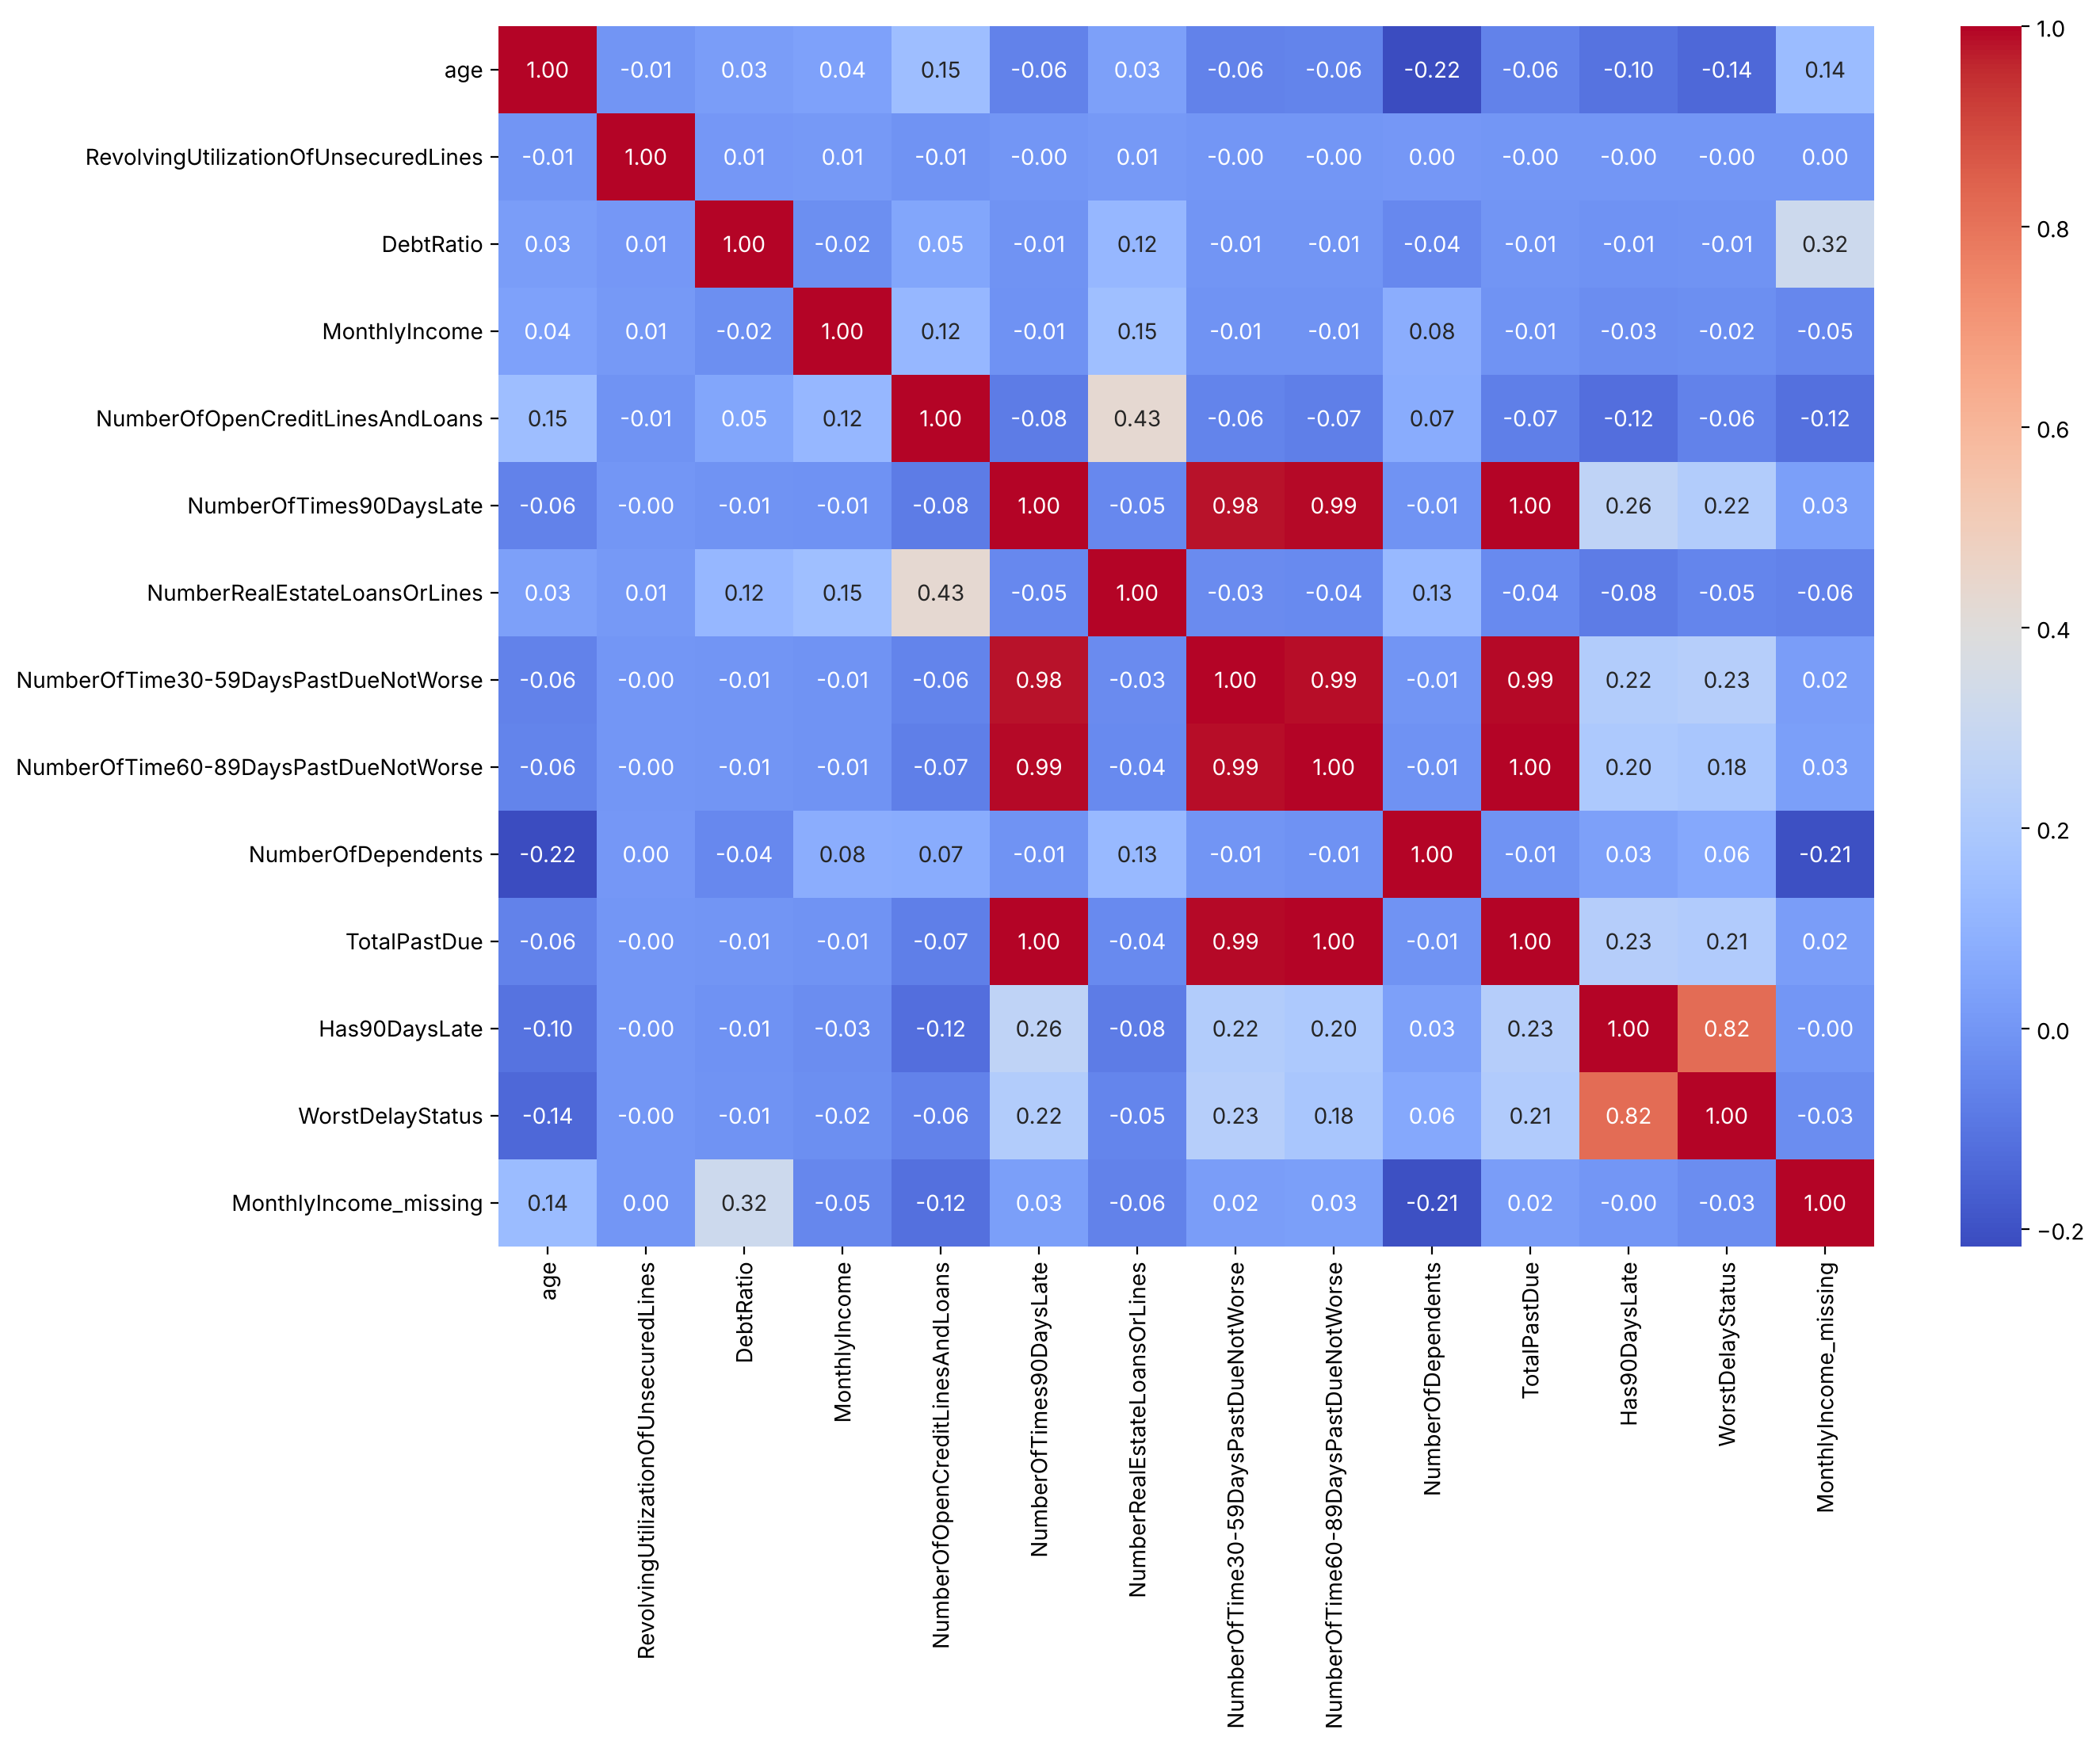

In [49]:
corr_matrix = X.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

## 18. Mutual information

TotalPastDue                            0.048215
WorstDelayStatus                        0.047337
RevolvingUtilizationOfUnsecuredLines    0.035976
NumberOfTimes90DaysLate                 0.031721
Has90DaysLate                           0.030859
NumberOfTime30-59DaysPastDueNotWorse    0.025193
NumberOfTime60-89DaysPastDueNotWorse    0.021518
age                                     0.007474
NumberRealEstateLoansOrLines            0.005868
NumberOfOpenCreditLinesAndLoans         0.004791
MonthlyIncome                           0.003877
DebtRatio                               0.003852
MonthlyIncome_missing                   0.002946
NumberOfDependents                      0.001421
dtype: float64


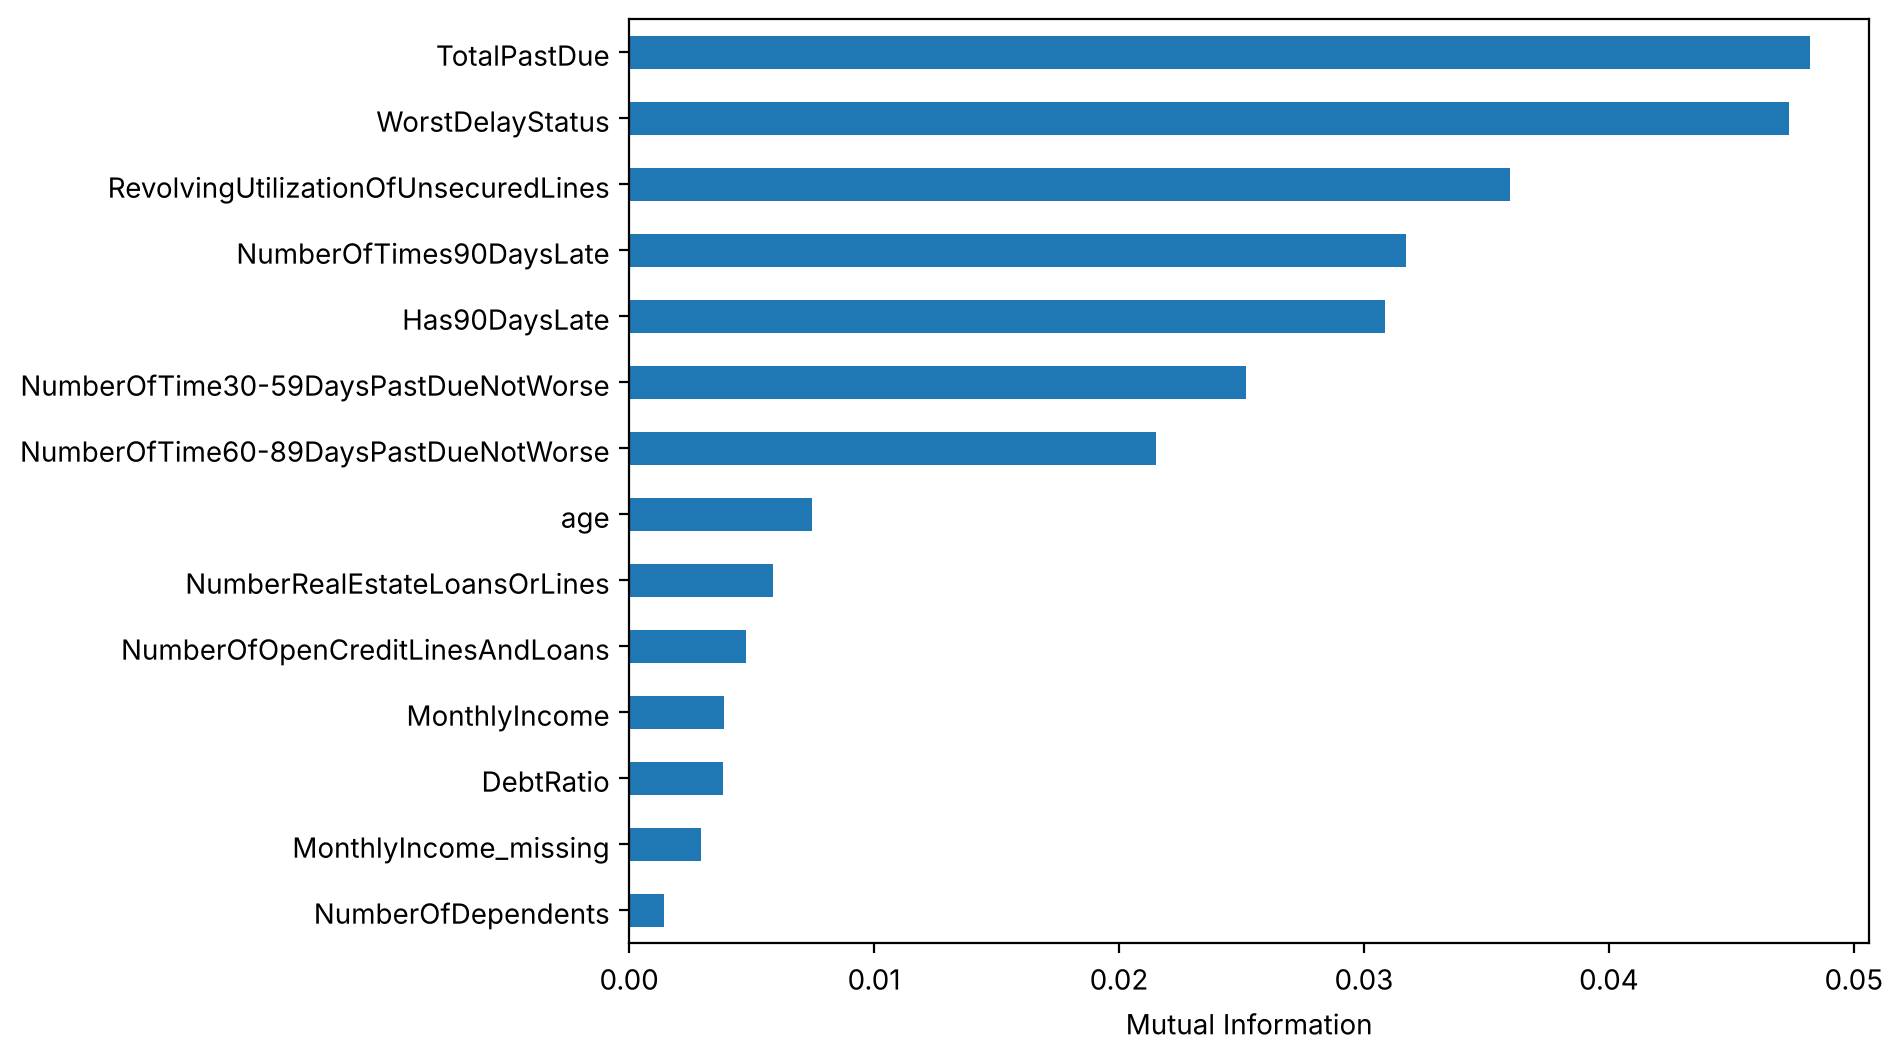

In [50]:
X = train_df.drop(columns=[target, "Is_Outlier"])
y = train_df[target]

mi = mutual_info_classif(X, y, random_state=42)

mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False)

print(mi_scores)

mi_scores.sort_values().plot.barh(figsize=(8, 6))
plt.xlabel("Mutual Information")
plt.show()

## 19. Train data summary

In [51]:
train_numeric_report = train_df.select_dtypes(include=np.number).describe().T

train_numeric_report

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,104990.0,6.604329,278.606072,0.0,0.029839,0.154304,0.562561,50708.0
age,104990.0,52.320840,14.757396,21.0,41.000000,52.000000,63.000000,99.0
NumberOfTime30-59DaysPastDueNotWorse,104990.0,0.428641,4.285956,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,104990.0,352.521767,2060.187704,0.0,0.175375,0.365676,0.864137,326442.0
MonthlyIncome,104990.0,6389.908067,9747.130035,0.0,3900.000000,5400.000000,7396.000000,1794060.0
NumberOfOpenCreditLinesAndLoans,104990.0,8.456748,5.149192,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,104990.0,0.274474,4.264272,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,104990.0,1.018421,1.126040,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,104990.0,0.248281,4.250066,0.0,0.000000,0.000000,0.000000,98.0
NumberOfDependents,104990.0,0.739442,1.106834,0.0,0.000000,0.000000,1.000000,10.0


In [52]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

train_df[new_features].head()

,WorstDelayStatus,TotalPastDue,Has90DaysLate
38102,0,0,0
111974,1,1,0
115712,0,0,0
119235,0,0,0
88057,0,0,0


In [53]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

train_df.groupby(target)[new_features].mean().T

SeriousDlqin,0,1
WorstDelayStatus,0.265798,1.486960
TotalPastDue,0.570994,6.262648
Has90DaysLate,0.035030,0.347727


## 20. Test data summary


In [54]:
test_numeric_report = test_df.select_dtypes(include=np.number).describe().T

test_numeric_report

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,44996.0,4.753191,163.791051,0.0,0.029959,0.154042,0.552770,17441.0
age,44996.0,52.221709,14.779871,21.0,41.000000,52.000000,62.000000,99.0
NumberOfTime30-59DaysPastDueNotWorse,44996.0,0.403347,3.967539,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,44996.0,354.125852,1984.953182,0.0,0.174154,0.368617,0.878103,329664.0
MonthlyIncome,44996.0,6485.801471,18227.441025,0.0,3916.000000,5400.000000,7400.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,44996.0,8.443995,5.138633,0.0,5.000000,8.000000,11.000000,57.0
NumberOfTimes90DaysLate,44996.0,0.246222,3.939477,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,44996.0,1.018002,1.138497,0.0,0.000000,1.000000,2.000000,29.0
NumberOfTime60-89DaysPastDueNotWorse,44996.0,0.222042,3.925534,0.0,0.000000,0.000000,0.000000,98.0
NumberOfDependents,44996.0,0.732843,1.107546,0.0,0.000000,0.000000,1.000000,20.0


In [55]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

test_df[new_features].head()

,WorstDelayStatus,TotalPastDue,Has90DaysLate
140392,2,4,0
94065,0,0,0
103070,0,0,0
141290,0,0,0
36347,0,0,0


In [56]:
summary_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate"
]

test_df.groupby(target)[summary_features].mean().T

SeriousDlqin,0,1
WorstDelayStatus,0.259003,1.495346
TotalPastDue,0.474493,6.414894
Has90DaysLate,0.034153,0.343085


In [57]:
train_df.to_csv("train.csv", index=False)
test_df.to_csv("test.csv", index=False)

## 21. Export check

`train.csv` and `test.csv` were written with `index=False`, so there is no extra `Unnamed: 0` column. `Is_Outlier` exists only in the training export (a diagnostic flag; the Random Forest notebook drops it).

In [58]:
chk_tr, chk_te = pd.read_csv("train.csv"), pd.read_csv("test.csv")
print("train.csv:", chk_tr.shape, "| test.csv:", chk_te.shape)
print("Unnamed index column present:", any(c.startswith("Unnamed") for c in chk_tr.columns.tolist() + chk_te.columns.tolist()))
print("Columns only in train:", set(chk_tr.columns) - set(chk_te.columns))
print("Columns only in test :", set(chk_te.columns) - set(chk_tr.columns))
print("Remaining NaNs  train/test:", int(chk_tr.isna().sum().sum()), int(chk_te.isna().sum().sum()))

train.csv: (104990, 16) | test.csv: (44996, 15)
Unnamed index column present: False
Columns only in train: {'Is_Outlier'}
Columns only in test : set()
Remaining NaNs  train/test: 0 0
